In [10]:
import scipy.io
import numpy as np

def load_cwru_file(filepath):
    mat = scipy.io.loadmat(filepath)
    de_key = [k for k in mat.keys() if 'DE_time' in k]
    if not de_key:
        raise ValueError(f"No DE_time channel found in {filepath}")
    signal = mat[de_key[0]].flatten()
    return signal

file_label_map = {
    "data/97.mat":  "Normal",
    "data/98.mat":  "Normal",      # 1HP
    "data/105.mat": "InnerRace",
    "data/106.mat": "InnerRace",   # 1HP
    "data/118.mat": "Ball",
    "data/119.mat": "Ball",        # 1HP
    "data/130.mat": "OuterRace",
    "data/131.mat": "OuterRace",   # 1HP
}

raw_signals = {}
for path, label in file_label_map.items():
    raw_signals[path] = {"signal": load_cwru_file(path), "label": label}
    print(f"{path}: {len(raw_signals[path]['signal'])} samples, label={label}")

data/97.mat: 243938 samples, label=Normal
data/98.mat: 483903 samples, label=Normal
data/105.mat: 121265 samples, label=InnerRace
data/106.mat: 121991 samples, label=InnerRace
data/118.mat: 122571 samples, label=Ball
data/119.mat: 121410 samples, label=Ball
data/130.mat: 121991 samples, label=OuterRace
data/131.mat: 122426 samples, label=OuterRace


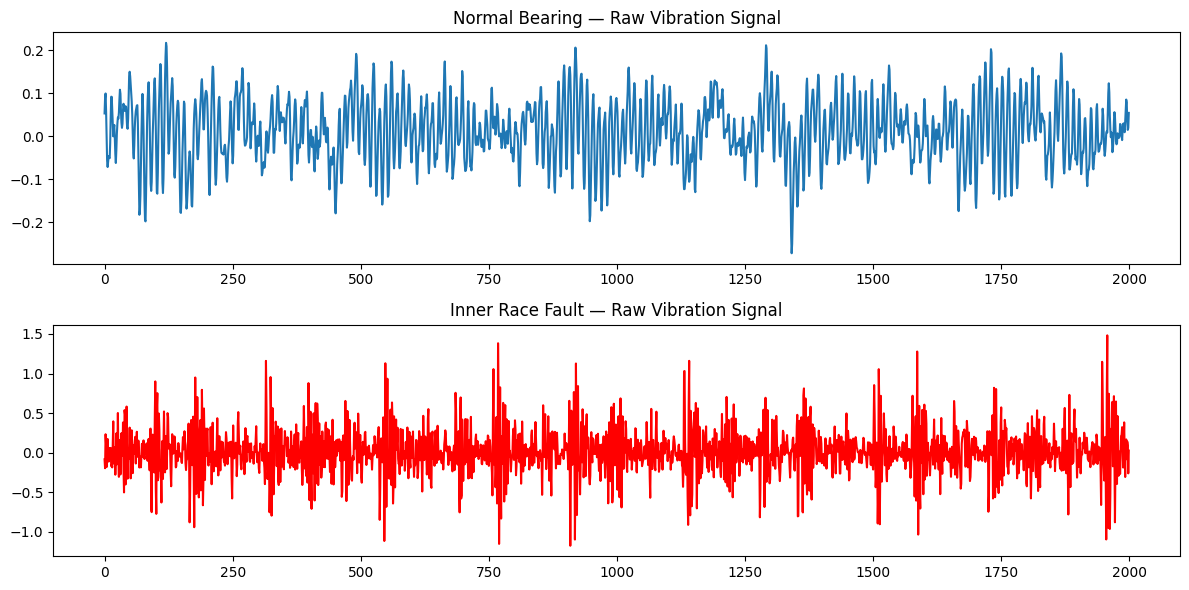

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
normal_sig = raw_signals["data/97.mat"]["signal"][:2000]
faulty_sig = raw_signals["data/105.mat"]["signal"][:2000]

axes[0].plot(normal_sig)
axes[0].set_title("Normal Bearing — Raw Vibration Signal")
axes[1].plot(faulty_sig, color='red')
axes[1].set_title("Inner Race Fault — Raw Vibration Signal")
plt.tight_layout()
plt.savefig("signal_comparison.png")
plt.show()

In [12]:
WINDOW_SIZE = 1024

def segment_signal(signal, window_size, file_id, label):
    n_windows = len(signal) // window_size
    windows = []
    for i in range(n_windows):
        w = signal[i*window_size : (i+1)*window_size]
        windows.append({"window": w, "file_id": file_id, "label": label})
    return windows

all_windows = []
for path, data in raw_signals.items():
    windows = segment_signal(data["signal"], WINDOW_SIZE, file_id=path, label=data["label"])
    all_windows.extend(windows)

print(f"Total windows created: {len(all_windows)}")

Total windows created: 1422


In [13]:
from scipy.stats import kurtosis, skew
import numpy as np

def extract_features(window):
    feats = {}
    feats["mean"] = np.mean(window)
    feats["rms"] = np.sqrt(np.mean(window**2))
    feats["std"] = np.std(window)
    feats["kurtosis"] = kurtosis(window)
    feats["skewness"] = skew(window)
    feats["peak"] = np.max(np.abs(window))
    feats["crest_factor"] = feats["peak"] / (feats["rms"] + 1e-8)

    fft_vals = np.abs(np.fft.rfft(window))
    freqs = np.fft.rfftfreq(len(window))
    feats["dominant_freq"] = freqs[np.argmax(fft_vals)]
    feats["spectral_energy"] = np.sum(fft_vals**2)
    psd_norm = fft_vals / (np.sum(fft_vals) + 1e-8)
    feats["spectral_entropy"] = -np.sum(psd_norm * np.log2(psd_norm + 1e-12))
    return feats

for w in all_windows:
    w["features"] = extract_features(w["window"])

print("Feature extraction done.")
print("Example features from first window:")
print(all_windows[0]["features"])

Feature extraction done.
Example features from first window:
{'mean': np.float64(0.01242096814903846), 'rms': np.float64(0.07598206978887359), 'std': np.float64(0.07495995250560014), 'kurtosis': np.float64(-0.24366426455323964), 'skewness': np.float64(-0.16297611297662787), 'peak': np.float64(0.21779446153846155), 'crest_factor': np.float64(2.866392472325484), 'dominant_freq': np.float64(0.0888671875), 'spectral_energy': np.float64(3107.747439546818), 'spectral_entropy': np.float64(7.281223078306587)}


In [14]:
import pandas as pd

rows = []
for w in all_windows:
    row = w["features"].copy()
    row["label"] = w["label"]
    row["file_id"] = w["file_id"]
    rows.append(row)

df = pd.DataFrame(rows)
df.to_csv("features_dataset.csv", index=False)
print(df.shape)
df.head()

(1422, 12)


,mean,rms,std,kurtosis,skewness,peak,crest_factor,dominant_freq,spectral_energy,spectral_entropy,label,file_id
0,0.012421,0.075982,0.074960,-0.243664,-0.162976,0.217794,2.866392,0.088867,3107.747440,7.281223,Normal,data/97.mat
1,0.011589,0.070425,0.069465,0.184817,-0.107386,0.272869,3.874579,0.085938,2670.753144,7.457917,Normal,data/97.mat
2,0.014643,0.078377,0.076996,-0.376182,0.050329,0.212370,2.709618,0.085938,3333.063813,7.221040,Normal,data/97.mat
3,0.010937,0.079688,0.078934,-0.034564,-0.163588,0.226765,2.845657,0.085938,3392.041600,7.221912,Normal,data/97.mat
4,0.013359,0.076104,0.074922,-0.321609,-0.028448,0.188588,2.478048,0.085938,3130.114064,7.357998,Normal,data/97.mat


In [17]:
from sklearn.model_selection import train_test_split

# Step 6a: Random stratified split (window-level — leakage-prone)
X = df.drop(columns=["label", "file_id"])
y = df["label"]

X_train_rand, X_test_rand, y_train_rand, y_test_rand = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

# Step 6b: File-level split — explicit, by load condition (0HP = train, 1HP = test)
# This guarantees every class appears in both train and test,
# and tests generalization across motor load — a stronger, more meaningful check.
train_files = ["data/97.mat", "data/105.mat", "data/118.mat", "data/130.mat"]   # all 0HP
test_files  = ["data/98.mat", "data/106.mat", "data/119.mat", "data/131.mat"]   # all 1HP

train_mask = df["file_id"].isin(train_files)
test_mask = df["file_id"].isin(test_files)

X_train_file = df[train_mask].drop(columns=["label", "file_id"])
y_train_file = df[train_mask]["label"]
X_test_file = df[test_mask].drop(columns=["label", "file_id"])
y_test_file = df[test_mask]["label"]

print("Random split -> train:", X_train_rand.shape, "test:", X_test_rand.shape)
print("File split   -> train:", X_train_file.shape, "test:", X_test_file.shape)
print("Train files:", train_files)
print("Test files:", test_files)

print("\nClasses in file-split TRAIN:", sorted(y_train_file.unique()))
print("Classes in file-split TEST: ", sorted(y_test_file.unique()))

Random split -> train: (1066, 10) test: (356, 10)
File split   -> train: (594, 10) test: (828, 10)
Train files: ['data/97.mat', 'data/105.mat', 'data/118.mat', 'data/130.mat']
Test files: ['data/98.mat', 'data/106.mat', 'data/119.mat', 'data/131.mat']

Classes in file-split TRAIN: ['Ball', 'InnerRace', 'Normal', 'OuterRace']
Classes in file-split TEST:  ['Ball', 'InnerRace', 'Normal', 'OuterRace']


In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_file)
X_test_scaled = scaler.transform(X_test_file)

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train_file)
y_test_enc = le.transform(y_test_file)

models = {
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
    "XGBoost": XGBClassifier(eval_metric="mlogloss", random_state=42)
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train_enc)
    trained_models[name] = model
    print(f"{name} trained.")

RandomForest trained.
SVM trained.


C:\Users\JOYDEEPA BANIK\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


XGBoost trained.


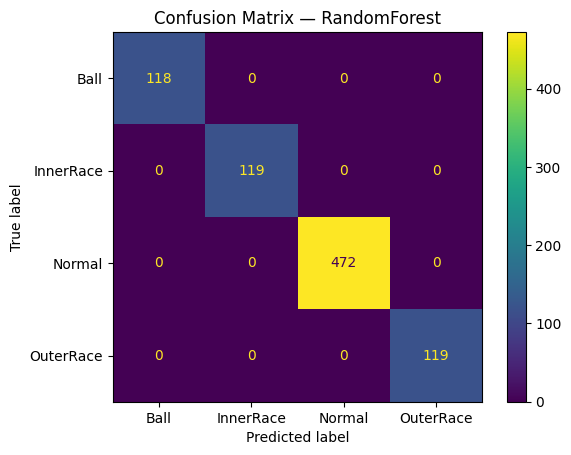

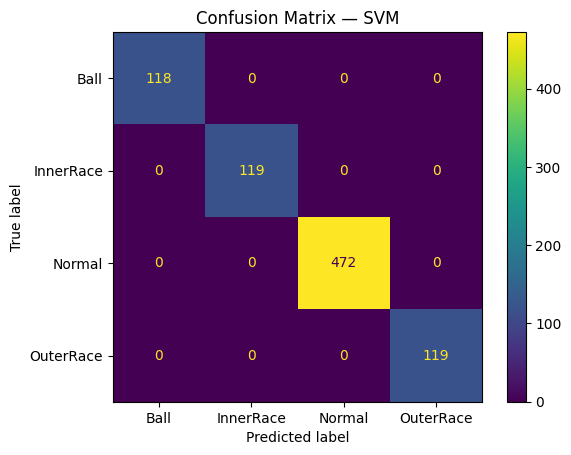

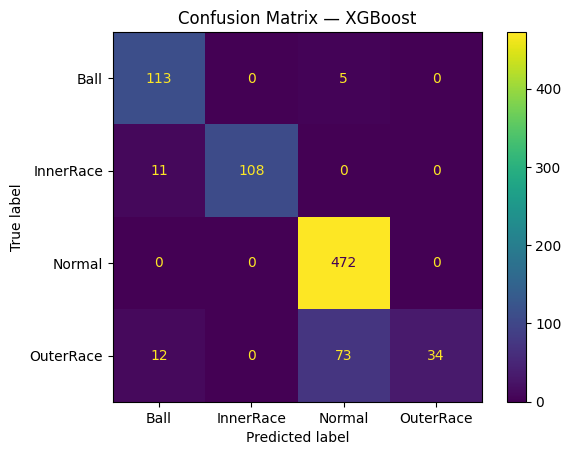

In [19]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

results = {}
for name, model in trained_models.items():
    preds = model.predict(X_test_scaled)
    acc = accuracy_score(y_test_enc, preds)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test_enc, preds, average="weighted")
    results[name] = {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

    cm = confusion_matrix(y_test_enc, preds)
    disp = ConfusionMatrixDisplay(cm, display_labels=le.classes_)
    disp.plot()
    plt.title(f"Confusion Matrix — {name}")
    plt.savefig(f"confusion_matrix_{name}.png")
    plt.show()

In [20]:
comparison_df = pd.DataFrame(results).T
comparison_df = comparison_df.round(4)
print(comparison_df)
comparison_df.to_csv("model_comparison.csv")

              accuracy  precision  recall     f1
RandomForest     1.000     1.0000   1.000  1.000
SVM              1.000     1.0000   1.000  1.000
XGBoost          0.878     0.8951   0.878  0.854


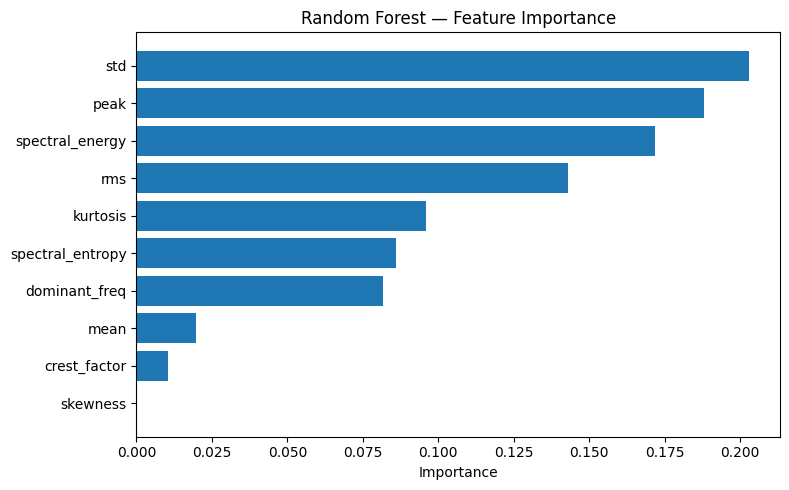

            feature  importance
2               std    0.203107
5              peak    0.187927
8   spectral_energy    0.171810
1               rms    0.143156
3          kurtosis    0.095958
9  spectral_entropy    0.085996
7     dominant_freq    0.081695
0              mean    0.019809
6      crest_factor    0.010343
4          skewness    0.000200


In [21]:
importances = trained_models["RandomForest"].feature_importances_
feat_names = X_train_file.columns
imp_df = pd.DataFrame({"feature": feat_names, "importance": importances})
imp_df = imp_df.sort_values("importance", ascending=False)

plt.figure(figsize=(8,5))
plt.barh(imp_df["feature"], imp_df["importance"])
plt.gca().invert_yaxis()
plt.title("Random Forest — Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()

print(imp_df)

In [22]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.preprocessing import LabelEncoder
import numpy as np

X_raw = np.stack([w["window"] for w in all_windows])
X_raw = (X_raw - X_raw.mean()) / X_raw.std()
X_raw = X_raw[..., np.newaxis]

y_raw = [w["label"] for w in all_windows]
le2 = LabelEncoder()
y_raw_enc = le2.fit_transform(y_raw)

file_ids = [w["file_id"] for w in all_windows]
train_mask_cnn = np.array([f in train_files for f in file_ids])
test_mask_cnn  = np.array([f in test_files  for f in file_ids])

X_tr, X_te = X_raw[train_mask_cnn], X_raw[test_mask_cnn]
y_tr, y_te = y_raw_enc[train_mask_cnn], y_raw_enc[test_mask_cnn]

cnn = models.Sequential([
    layers.Conv1D(16, 9, activation="relu", input_shape=(1024,1)),
    layers.MaxPooling1D(4),
    layers.Conv1D(32, 9, activation="relu"),
    layers.MaxPooling1D(4),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(le2.classes_), activation="softmax")
])

cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = cnn.fit(X_tr, y_tr, validation_data=(X_te, y_te), epochs=15, batch_size=32)

cnn_acc = cnn.evaluate(X_te, y_te)[1]
print(f"\nCNN test accuracy: {cnn_acc:.4f}")
print(f"Classical models for comparison: {comparison_df['accuracy'].to_dict()}")

C:\Users\JOYDEEPA BANIK\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.4966 - loss: 1.1054 - val_accuracy: 0.8539 - val_loss: 0.7606
Epoch 2/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8788 - loss: 0.4469 - val_accuracy: 1.0000 - val_loss: 0.1508
Epoch 3/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9865 - loss: 0.1286 - val_accuracy: 1.0000 - val_loss: 0.0353
Epoch 4/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9966 - loss: 0.0458 - val_accuracy: 1.0000 - val_loss: 0.0232
Epoch 5/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9899 - loss: 0.0523 - val_accuracy: 1.0000 - val_loss: 0.0169
Epoch 6/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9983 - loss: 0.0252 - val_accuracy: 1.0000 - val_loss: 0.0101
Epoch 7/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 1.0000 - loss: 0.0124 - val_accuracy: 1.0000 - val_loss: 0.0024
Epoch 8/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9983 - loss: 0.0142 - val_accuracy: 1.0000 - v

In [23]:
import joblib

joblib.dump(trained_models["RandomForest"], "model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(le, "label_encoder.pkl")

print("Saved: model.pkl, scaler.pkl, label_encoder.pkl")

Saved: model.pkl, scaler.pkl, label_encoder.pkl
